In [ ]:
import jax
import jax.numpy as jnp

from hcnn.constraint.constraint_state_outside_sphere import ConstraintStateOutsideSphere
from hcnn.environment import Environment
from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.system.system_linear import SystemLinear

state_matrix = jnp.array([[1, -1], [1, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemLinear.factory(state_matrix, input_matrix)
policy = PolicyLQR.factory(system, state_cost, input_cost)
constraint = ConstraintStateOutsideSphere.factory(center=jnp.array([1, 1]), radius=1.0)
environment = Environment(system, policy)

In [2]:
policy

PolicyLQR(state_cost=Array([[1., 0.],
       [0., 1.]], dtype=float32), input_cost=Array([[1.]], dtype=float32), riccati_matrix=Array([[ 3.1301594, -0.6101485],
       [-0.6101485,  1.7578782]], dtype=float32), gain_matrix=Array([[ 0.61014867, -0.75787866]], dtype=float32))

In [7]:
view_range = 2.0
samples_per_axis = 15
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
next_states = jax.vmap(environment.step, in_axes=(0))(states)
difference = next_states - states
unit_difference = difference / jnp.linalg.norm(difference, axis=-1, keepdims=True)

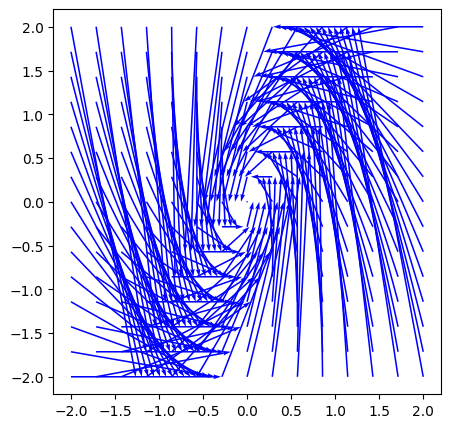

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
)
plt.show()

In [9]:
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
value = jax.vmap(policy.get_value, in_axes=(0))(states)

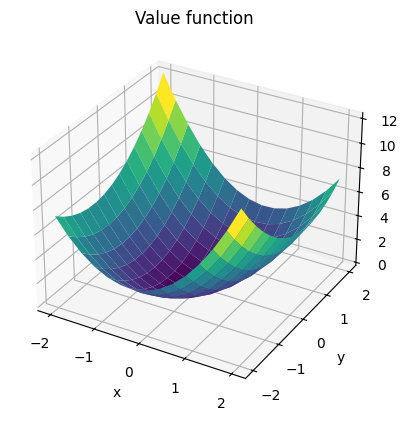

In [10]:
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, value.reshape(X.shape), cmap="viridis")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Value function")
plt.show()